# AI-Driven Credit Card Fraud Detection
Arch Store — SOC Scenario

## Cell 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

%matplotlib inline

## Cell 2: Load & Analyze Data

Total Transactions: 284807
Fraudulent Transactions: 492
Legitimate Transactions: 284315


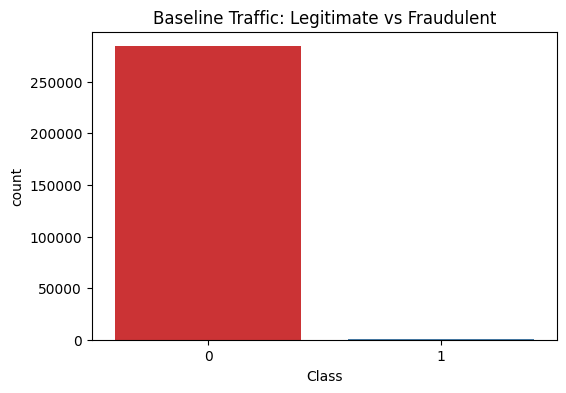

In [2]:
# Load dataset
df = pd.read_csv('data/creditcard.csv')
print("Total Transactions:", df.shape[0])
print("Fraudulent Transactions:", df['Class'].sum())
print("Legitimate Transactions:", df['Class'].value_counts()[0])

# Visualize the imbalance
plt.figure(figsize=(6,4))
sns.countplot(x='Class', data=df, hue='Class', palette='Set1', legend=False)
plt.title('Baseline Traffic: Legitimate vs Fraudulent')
plt.show()

## Cell 3: Data Preprocessing

In [3]:
scaler = StandardScaler()
df['scaled_amount'] = scaler.fit_transform(df['Amount'].values.reshape(-1,1))
df['scaled_time'] = scaler.fit_transform(df['Time'].values.reshape(-1,1))
df.drop(['Time', 'Amount'], axis=1, inplace=True)

X = df.drop('Class', axis=1)
y = df['Class']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

## Cell 4: Handling Imbalance (The SOC Challenge)

In [4]:
# Kyunke fraud bohot kam hai, model ko sikhane ke liye SMOTE use kar rahe hain
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("Original Training Data:", len(y_train))
print("Balanced Training Data (after SMOTE):", len(y_train_resampled))

Original Training Data: 227845
Balanced Training Data (after SMOTE): 454902


## Cell 5: Train the Detection Model

In [5]:
# Random Forest supervised fraud classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_resampled, y_train_resampled)
print("Detection Engine Trained Successfully!")

Detection Engine Trained Successfully!


## Cell 6: Evaluation & SOC Alert Triage

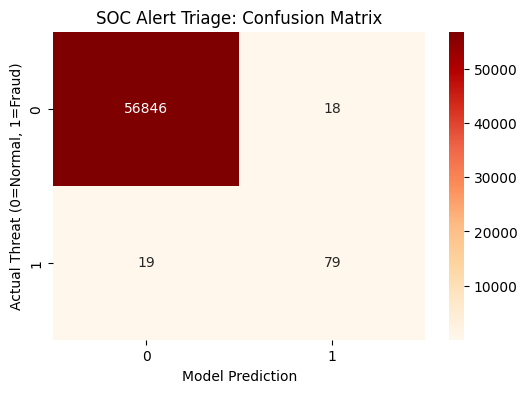


--- SOC Detection Report ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.81      0.81      0.81        98

    accuracy                           1.00     56962
   macro avg       0.91      0.90      0.90     56962
weighted avg       1.00      1.00      1.00     56962



In [6]:
y_pred = rf_model.predict(X_test)

# Confusion Matrix (False Positives vs False Negatives)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='OrRd')
plt.title('SOC Alert Triage: Confusion Matrix')
plt.ylabel('Actual Threat (0=Normal, 1=Fraud)')
plt.xlabel('Model Prediction')
plt.show()

print("\n--- SOC Detection Report ---")
print(classification_report(y_test, y_pred))